
# 3. Horizon graph: representació compacta de sèries temporals

## Objectiu

Explorar la tècnica del *horizon graph* per representar l'evolució d'una variable numèrica al llarg del temps.

Aquesta tècnica divideix els valors d'una sèrie temporal en bandes de color i permet representar-ne les variacions en un espai reduït. És especialment útil per comparar moltes sèries temporals i detectar patrons, tendències i fluctuacions.

En aquesta activitat s'utilitzarà un conjunt de dades obert que permeti aplicar la tècnica i analitzar quina informació comunica de manera més efectiva.


In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ruta del fitxer CSV
BASE_DIR = Path.cwd().resolve()

CSV_PATH = (
    BASE_DIR.parent
    / "dades horizon graph"
    / "average-monthly-surface-temperature.csv"
)

# Carregar les dades
df = pd.read_csv(CSV_PATH)

# Explorar el conjunt de dades
print("Dimensions del conjunt de dades:", df.shape)

print("\nColumnes:")
print(df.columns.tolist())

print("\nValors absents:")
print(df.isna().sum())

print("\nNombre d'entitats:", df["Entity"].nunique())

print("\nPeríode disponible:")
print(df["Month"].min(), "–", df["Month"].max())

display(df.head())


Dimensions del conjunt de dades: (221733, 4)

Columnes:
['Entity', 'Code', 'Month', 'Monthly average']

Valors absents:
Entity                 0
Code               18738
Month                  0
Monthly average        0
dtype: int64

Nombre d'entitats: 213

Període disponible:
1940-01 – 2026-09


,Entity,Code,Month,Monthly average
0,Afghanistan,AFG,1940-01,-2.032494
1,Afghanistan,AFG,1940-02,-0.733503
2,Afghanistan,AFG,1940-03,1.999134
3,Afghanistan,AFG,1940-04,10.199754
4,Afghanistan,AFG,1940-05,17.942135


In [2]:

# Preparar les dates i els valors numèrics
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
df["Monthly average"] = pd.to_numeric(
    df["Monthly average"],
    errors="coerce"
)

# Països que volem comparar
paisos = [
    "Spain",
    "France",
    "Germany",
    "Canada",
    "Japan",
    "Australia"
]

# Seleccionar les dades del període 1990–2025
dades = df[
    df["Entity"].isin(paisos)
    & df["Month"].between("1990-01-01", "2025-12-31")
].copy()

# Comprovar quines sèries tenim disponibles
resum = (
    dades.groupby("Entity")
    .agg(
        observacions=("Monthly average", "count"),
        primer_mes=("Month", "min"),
        ultim_mes=("Month", "max"),
        valors_absents=("Monthly average", lambda x: x.isna().sum())
    )
)

display(resum)

print("Països trobats:", sorted(dades["Entity"].unique()))
print("Nombre de països:", dades["Entity"].nunique())


,observacions,primer_mes,ultim_mes,valors_absents
Entity,,,,
Australia,432,1990-01-01,2025-12-01,0
Canada,432,1990-01-01,2025-12-01,0
France,432,1990-01-01,2025-12-01,0
Germany,432,1990-01-01,2025-12-01,0
Japan,432,1990-01-01,2025-12-01,0
Spain,432,1990-01-01,2025-12-01,0


Països trobats: ['Australia', 'Canada', 'France', 'Germany', 'Japan', 'Spain']
Nombre de països: 6


In [3]:

# Seleccionar el període de referència 1991–2020
referencia = dades[
    dades["Month"].between("1991-01-01", "2020-12-31")
].copy()

# Extreure el número de mes
referencia["mes"] = referencia["Month"].dt.month
dades["mes"] = dades["Month"].dt.month

# Calcular la temperatura mitjana de cada mes per a cada país
mitjanes_mensuals = (
    referencia.groupby(["Entity", "mes"])["Monthly average"]
    .mean()
    .rename("mitjana_referencia")
    .reset_index()
)

# Afegir les mitjanes de referència a totes les observacions
dades_anomalia = dades.merge(
    mitjanes_mensuals,
    on=["Entity", "mes"],
    how="left"
)

# Calcular les anomalies de temperatura
dades_anomalia["anomalia"] = (
    dades_anomalia["Monthly average"]
    - dades_anomalia["mitjana_referencia"]
)

display(
    dades_anomalia[
        ["Entity", "Month", "Monthly average",
         "mitjana_referencia", "anomalia"]
    ].head(12)
)

print("Valors absents a les anomalies:",
      dades_anomalia["anomalia"].isna().sum())


,Entity,Month,Monthly average,mitjana_referencia,anomalia
0,Australia,1990-01-01,28.435526,28.350079,0.085447
1,Australia,1990-02-01,26.889010,27.533252,-0.644242
2,Australia,1990-03-01,26.772211,25.725262,1.046949
3,Australia,1990-04-01,22.190685,22.556667,-0.365982
4,Australia,1990-05-01,19.009030,18.250437,0.758593
5,Australia,1990-06-01,14.457963,15.203710,-0.745747
6,Australia,1990-07-01,14.788637,14.719167,0.069470
7,Australia,1990-08-01,15.786237,16.478989,-0.692752
8,Australia,1990-09-01,19.453972,20.251369,-0.797397
9,Australia,1990-10-01,23.422716,23.568553,-0.145837


Valors absents a les anomalies: 0


In [4]:

# Preparar la matriu de dades per al horizon graph
horizon_data = (
    dades_anomalia
    .pivot(
        index="Month",
        columns="Entity",
        values="anomalia"
    )
    .sort_index()
)

# Mantenir l'ordre dels països del gràfic
horizon_data = horizon_data.reindex(columns=paisos)

display(horizon_data.head())

print("Dimensions de la matriu:", horizon_data.shape)
print("Valors absents:", horizon_data.isna().sum().sum())


Entity,Spain,France,Germany,Canada,Japan,Australia
Month,,,,,,
1990-01-01,-0.376031,0.211902,1.490608,-0.457348,-1.115871,0.085447
1990-02-01,2.883082,3.518030,4.279545,-4.193396,2.254014,-0.644242
1990-03-01,0.503308,0.679234,2.335124,1.843876,0.908024,1.046949
1990-04-01,-1.883982,-1.487535,-1.648561,-0.177426,-0.018216,-0.365982
1990-05-01,0.364231,1.166174,0.664224,-0.740200,-0.169144,0.758593


Dimensions de la matriu: (432, 6)
Valors absents: 0


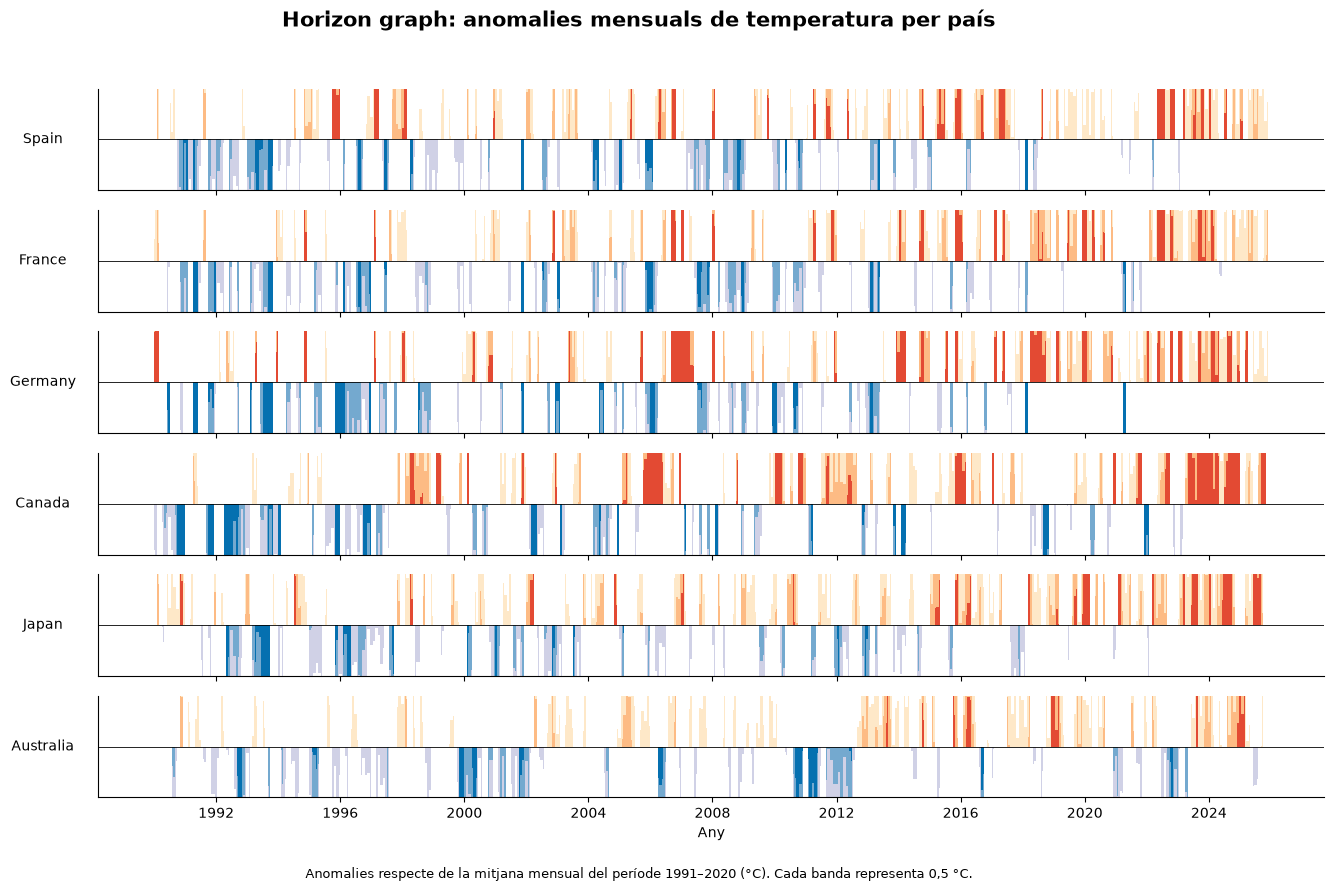

In [5]:

# Configuració de les bandes del horizon graph
amplada_banda = 0.5
nombre_bandes = 3
llindar_maxim = amplada_banda * nombre_bandes

colors_positius = ["#fee8c8", "#fdbb84", "#e34a33"]
colors_negatius = ["#d0d1e6", "#74a9cf", "#0570b0"]

fig, axes = plt.subplots(
    nrows=len(paisos),
    ncols=1,
    figsize=(14, 9),
    sharex=True
)

for ax, pais in zip(axes, paisos):
    dates = horizon_data.index
    valors = horizon_data[pais].to_numpy(dtype=float)

    # Limitar les anomalies al rang representat
    valors_limitats = np.clip(
        valors,
        -llindar_maxim,
        llindar_maxim
    )

    valors_absoluts = np.abs(valors_limitats)
    valors_valids = np.isfinite(valors_limitats)

    # Dibuixar les bandes de menor a major magnitud.
    # Les bandes superiors se superposen a les inferiors.
    for banda in range(nombre_bandes):
        llindar = banda * amplada_banda

        alçada = np.clip(
            valors_absoluts - llindar,
            0,
            amplada_banda
        )

        # Cada banda només apareix quan se supera el seu llindar
        mascara_positiva = (
            valors_valids
            & (valors_limitats > llindar)
        )

        mascara_negativa = (
            valors_valids
            & (valors_limitats < -llindar)
        )

        # Anomalies positives: colors càlids
        ax.fill_between(
            dates,
            0,
            alçada,
            where=mascara_positiva,
            step="mid",
            color=colors_positius[banda],
            linewidth=0
        )

        # Anomalies negatives: colors freds
        ax.fill_between(
            dates,
            -alçada,
            0,
            where=mascara_negativa,
            step="mid",
            color=colors_negatius[banda],
            linewidth=0
        )

    # Línia de referència
    ax.axhline(0, color="black", linewidth=0.6)

    # Escala vertical comuna per comparar els països
    ax.set_ylim(-amplada_banda, amplada_banda)
    ax.set_ylabel(pais, rotation=0, labelpad=40, va="center")
    ax.set_yticks([])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Any")

fig.suptitle(
    "Horizon graph: anomalies mensuals de temperatura per país",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.5,
    0.015,
    "Anomalies respecte de la mitjana mensual del període 1991–2020 (°C). "
    "Cada banda representa 0,5 °C.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0.04, 0.04, 1, 0.95])
plt.show()


In [6]:
# Desar el gràfic
OUTPUT_DIR = BASE_DIR / "grafics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "horizon_graph_temperatures.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

print(f"Horizon graph desat a: {output_path}")

Horizon graph desat a: D:\ESTUDIS\Master data science - UOC\1r_Semestre\Visualització de Dades\PAC2\entregable\grafics\horizon_graph_temperatures.png



## Interpretació dels resultats

El gràfic d'horitzó (*horizon graph*) representa l'evolució mensual de les anomalies de temperatura de sis països: Espanya, França, Alemanya, el Canadà, el Japó i Austràlia, durant el període 1990–2025. Les anomalies s'han calculat respecte de la mitjana de cada mes durant el període de referència 1991–2020.

Les bandes de color permeten distingir les anomalies positives de les negatives. Els tons càlids representen temperatures superiors a la mitjana de referència, mentre que els tons freds indiquen temperatures inferiors. La intensitat del color reflecteix la magnitud de l'anomalia, agrupada en intervals de 0,5 °C.

La representació permet observar com varien les anomalies al llarg del temps i comparar-ne els patrons entre països. En els anys més recents s'hi aprecia una presència més freqüent de bandes càlides en diverses sèries, mentre que en períodes anteriors també hi ha episodis amb anomalies negatives destacables. Aquest patró és especialment visible en observar conjuntament les sis sèries temporals.

L'objectiu comunicatiu és facilitar la comparació de diverses sèries temporals en un espai vertical reduït. El gràfic d'horitzó és adequat per a aquesta finalitat perquè comprimeix la representació de les variacions i permet identificar períodes amb anomalies de diferent signe i magnitud.

Cal tenir en compte que les anomalies s'han calculat respecte de la mitjana mensual de cada país i que, per tant, el gràfic mostra desviacions respecte del patró climàtic de referència, no temperatures absolutes. A més, les bandes agrupen els valors en intervals i els valors que superen el límit màxim representat queden saturats en l'última banda. Això facilita la comparació visual, però limita la lectura dels valors exactes.
